# Urbane Luftverschmutzung: Feature Engineering mit Gradient Boosting

Aufbauend auf der Baseline (Meilenstein 2: Gradient Boosting auf 8 Rohfeatures)
testen wir hier systematisch, welche **neuen Features** dem Modell
helfen. Das Gradient-Boosting-Modell ist dabei das Messinstrument:

1. Feature-Gruppen bauen (Datum, abgeleitetes Wetter, abgeleitete Satellitenwerte,
   Orts-Aggregate, Tages-Aggregate, zeitliche Glättung).
2. Jede Gruppe schrittweise hinzufügen und per `GroupKFold` nach `Place_ID`
   messen, was sie bringt (Ablation).
3. Mit Permutation Importance des Gradient-Boosting-Modells die Features
   auswählen (verschachtelt, ohne die Validierungsorte zu nutzen).

**Wichtige Regeln**

- Train und Test enthalten **keine gemeinsamen Orte**. Features dürfen daher
  keine Ortskennung sein (kein `Place_ID`-Encoding, keine Target-Mittelwerte pro Ort).
- Aggregate pro Ort oder Tag werden nur aus **Features** berechnet, nie aus dem
  Target, und in Train und Test getrennt. Das ist auch im Test möglich, weil dort
  ebenfalls viele Tage pro Ort vorliegen.
- `target_min/max/variance/count` gibt es nur in Train (Leakage) und werden nicht verwendet.
- Die Winkel- und Höhenspalten der Satelliten (`sensor_*`, `solar_*`) fallen weg.
  Wie die Auswertung zeigte, sind sie weitgehend Ortskennungen ohne
  eigene Information.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
DATA_DIR = Path("data")

## 1. Daten laden

In [2]:
train = pd.read_csv(DATA_DIR / "Train.csv", parse_dates=["Date"])
test = pd.read_csv(DATA_DIR / "Test.csv", parse_dates=["Date"])

target = "target"
meta_cols = ["Place_ID X Date", "Date", "Place_ID"]
geometry_markers = ("sensor_azimuth", "sensor_zenith", "solar_azimuth",
                    "solar_zenith", "sensor_altitude")

raw_cols = [c for c in test.columns if c not in meta_cols]
geometry_cols = [c for c in raw_cols if any(m in c for m in geometry_markers)]
raw_features = [c for c in raw_cols if c not in geometry_cols]
print(f"Rohspalten: {len(raw_cols)}, davon Geometrie (entfernt): {len(geometry_cols)}, "
      f"übrig: {len(raw_features)}")
print(f"Orte Train/Test: {train.Place_ID.nunique()} / {test.Place_ID.nunique()}, "
      f"gemeinsame Orte: {len(set(train.Place_ID) & set(test.Place_ID))}")

Rohspalten: 74, davon Geometrie (entfernt): 35, übrig: 39
Orte Train/Test: 340 / 179, gemeinsame Orte: 0


## 2. Feature-Gruppen bauen

`build_features` arbeitet auf **einem** Datensatz (Train oder Test) und gibt
die Features nach Gruppen sortiert zurück.

| Gruppe | Inhalt | Idee |
| --- | --- | --- |
| `baseline` | 8 Features aus Meilenstein 2 | Referenz |
| `roh` | alle übrigen Rohspalten ohne Geometrie | mehr Signal, mehr Rauschen |
| `datum` | Tag im Jahr, Wochentag, Wochenende | Saison, Verkehr |
| `wetter` | Windgeschwindigkeit und -richtung, Feuchte mal Temperatur, Taupunktabstand | Ausbreitung und Bindung von Partikeln |
| `satellit` | Verhältnisse (NO2 troposphärisch/gesamt, CO/H2O), mittlere Bewölkung, Anzahl fehlender Satellitenwerte | Qualität und Bewölkung der Messung |
| `ort` | Mittelwert, Streuung und Abweichung pro Ort über alle Tage | Grundbelastung eines Ortes (62 % der Varianz liegt zwischen Orten) |
| `tag` | Mittelwert und Abweichung pro Tag über alle Orte | regionale Wetterlage und Tagesniveau |
| `zeit` | gleitender Mittelwert über 3 und 7 Tage pro Ort | Satellitenwerte sind lückenhaft und verrauscht |

Logarithmen oder Standardisierung lassen wir weg: Baumverfahren sind
gegenüber monotonen Transformationen invariant.

In [3]:
BASELINE = [
    "wind_speed",
    "L3_HCHO_tropospheric_HCHO_column_number_density",
    "L3_CO_CO_column_number_density",
    "L3_NO2_NO2_column_number_density",
    "L3_SO2_absorbing_aerosol_index",
    "L3_CLOUD_cloud_fraction",
    "dayofyear",
    "weekday",
]

# Schlüsselfeatures, für die Aggregate gebildet werden
KEY = [
    "wind_speed",
    "temperature_2m_above_ground",
    "relative_humidity_2m_above_ground",
    "precipitable_water_entire_atmosphere",
    "L3_NO2_NO2_column_number_density",
    "L3_NO2_tropospheric_NO2_column_number_density",
    "L3_CO_CO_column_number_density",
    "L3_HCHO_tropospheric_HCHO_column_number_density",
    "L3_SO2_SO2_column_number_density",
    "L3_O3_O3_column_number_density",
    "L3_AER_AI_absorbing_aerosol_index",
    "L3_CLOUD_cloud_fraction",
    "L3_CLOUD_surface_albedo",
    "L3_CH4_CH4_column_volume_mixing_ratio_dry_air",
]
ROLL_KEY = [c for c in KEY if c.startswith("L3_")]
CLOUD_COLS = [c for c in raw_cols if c.endswith("cloud_fraction")]


def build_features(df):
    """Baut alle Features für einen Datensatz. Gibt (df, Features, Gruppen) zurück."""
    df = df.reset_index(drop=True)  # Zeilenreihenfolge bleibt wie in der Datei (gleiche Folds wie in Meilenstein 2)
    out = pd.DataFrame(index=df.index)
    groups = {}

    # Datum
    out["dayofyear"] = df["Date"].dt.day_of_year
    out["weekday"] = df["Date"].dt.day_of_week
    out["is_weekend"] = (out["weekday"] >= 5).astype(int)
    groups["datum"] = ["dayofyear", "weekday", "is_weekend"]

    # Abgeleitetes Wetter
    u = df["u_component_of_wind_10m_above_ground"]
    v = df["v_component_of_wind_10m_above_ground"]
    t = df["temperature_2m_above_ground"]
    rh = df["relative_humidity_2m_above_ground"]
    out["wind_speed"] = np.sqrt(u**2 + v**2)
    out["wind_dir_sin"] = v / out["wind_speed"].replace(0, np.nan)
    out["wind_dir_cos"] = u / out["wind_speed"].replace(0, np.nan)
    out["temp_x_humidity"] = t * rh
    # Magnus-Näherung für den Taupunkt (t in Celsius, falls Werte in Kelvin vorliegen)
    t_c = t - 273.15 if t.median() > 100 else t
    gamma = np.log(rh.clip(lower=1) / 100) + 17.62 * t_c / (243.12 + t_c)
    out["dewpoint_gap"] = t_c - 243.12 * gamma / (17.62 - gamma)
    groups["wetter"] = ["wind_speed", "wind_dir_sin", "wind_dir_cos",
                        "temp_x_humidity", "dewpoint_gap"]

    # Rohspalten (ohne Geometrie), ohne schon berechnete Spalten
    roh = [c for c in raw_features if c not in out.columns]
    out = pd.concat([out, df[roh]], axis=1)
    groups["roh"] = roh

    # Abgeleitete Satellitenwerte
    sat = pd.DataFrame(index=df.index)
    sat["no2_trop_share"] = (df["L3_NO2_tropospheric_NO2_column_number_density"]
                             / df["L3_NO2_NO2_column_number_density"].replace(0, np.nan))
    sat["no2_slant_ratio"] = (df["L3_NO2_NO2_slant_column_number_density"]
                              / df["L3_NO2_NO2_column_number_density"].replace(0, np.nan))
    sat["co_h2o_ratio"] = (df["L3_CO_CO_column_number_density"]
                           / df["L3_CO_H2O_column_number_density"].replace(0, np.nan))
    sat["cloud_mean"] = df[CLOUD_COLS].mean(axis=1)
    sat["sat_missing_count"] = df[[c for c in raw_features if c.startswith("L3_")]].isna().sum(axis=1)
    sat = sat.replace([np.inf, -np.inf], np.nan)
    out = pd.concat([out, sat], axis=1)
    groups["satellit"] = list(sat.columns)

    base = pd.DataFrame({c: (out[c] if c in out.columns else df[c]) for c in KEY})

    # Ort-Aggregate (nur Features, keine Targets)
    ort = {}
    g_place = base.groupby(df["Place_ID"])
    for stat in ("mean", "std"):
        agg = g_place.transform(stat)
        for c in KEY:
            ort[f"{c}__ort_{stat}"] = agg[c]
    mean_place = g_place.transform("mean")
    for c in KEY:
        ort[f"{c}__ort_dev"] = base[c] - mean_place[c]
    ort = pd.DataFrame(ort)
    out = pd.concat([out, ort], axis=1)
    groups["ort"] = list(ort.columns)

    # Tages-Aggregate über alle Orte desselben Datensatzes
    tag = {}
    mean_day = base.groupby(df["Date"]).transform("mean")
    for c in KEY:
        tag[f"{c}__tag_mean"] = mean_day[c]
        tag[f"{c}__tag_dev"] = base[c] - mean_day[c]
    tag = pd.DataFrame(tag)
    out = pd.concat([out, tag], axis=1)
    groups["tag"] = list(tag.columns)

    # Zeitliche Glättung pro Ort (zentrierter gleitender Mittelwert)
    zeit = {}
    for w in (3, 7):
        # nach Ort und Datum sortieren, glätten, dann in die Originalreihenfolge zurück
        order_idx = df.sort_values(["Place_ID", "Date"]).index
        srt = base.loc[order_idx, ROLL_KEY]
        roll = (srt.groupby(df.loc[order_idx, "Place_ID"])
                .rolling(w, center=True, min_periods=1).mean()
                .reset_index(level=0, drop=True).sort_index())
        for c in ROLL_KEY:
            zeit[f"{c}__roll{w}"] = roll[c]
    zeit = pd.DataFrame(zeit)
    out = pd.concat([out, zeit], axis=1)
    groups["zeit"] = list(zeit.columns)

    return df, out, groups


train_s, Xtr_all, groups = build_features(train)
test_s, Xte_all, _ = build_features(test)
y = train_s[target]
place = train_s["Place_ID"]
assert list(Xtr_all.columns) == list(Xte_all.columns)
groups = {"baseline": BASELINE, **groups}
print(f"Alle Features: {Xtr_all.shape[1]}")
pd.Series({k: len(v) for k, v in groups.items()}, name="Anzahl Features").to_frame()

Alle Features: 142


,Anzahl Features
baseline,8
datum,3
wetter,5
roh,39
satellit,5
ort,42
tag,28
zeit,20


## 3. Validierung und Bewertungsfunktion

Wie in Meilenstein 2: 5-fach `GroupKFold` nach `Place_ID` und
`HistGradientBoostingRegressor` mit Standardparametern. Die Modelleinstellungen
bleiben für alle Experimente gleich, damit Unterschiede nur von den
Features kommen. Tuning folgt in Meilenstein 3.

In [4]:
folds = list(GroupKFold(n_splits=5).split(Xtr_all, y, place))


def make_model():
    return HistGradientBoostingRegressor(random_state=RANDOM_STATE)


def cv_score(cols, name=""):
    oof = np.zeros(len(y))
    for tr_idx, va_idx in folds:
        m = make_model().fit(Xtr_all.iloc[tr_idx][cols], y.iloc[tr_idx])
        oof[va_idx] = m.predict(Xtr_all.iloc[va_idx][cols])
    fold_rmse = [np.sqrt(mean_squared_error(y.iloc[va], oof[va])) for _, va in folds]
    return oof, {"Variante": name, "Features": len(cols),
                 "RMSE": np.sqrt(mean_squared_error(y, oof)),
                 "RMSE Fold-Std": np.std(fold_rmse),
                 "MAE": mean_absolute_error(y, oof), "R²": r2_score(y, oof)}


oof_base, row = cv_score(groups["baseline"], "Baseline (8 Features)")
print(f"Kontrolle Baseline: RMSE {row['RMSE']:.2f} (Meilenstein 2 mit allen 76 Rohspalten: 33,4)")

Kontrolle Baseline: RMSE 37.00 (Meilenstein 2 mit allen 76 Rohspalten: 33,4)


## 4. Ablation: Gruppen schrittweise hinzufügen

Wir starten bei der Baseline und fügen die Gruppen nacheinander hinzu. Die
Reihenfolge geht von „billig“ zu „aufwendig“. Zusätzlich messen wir jede
Gruppe **einzeln zur Baseline** (zeigt den eigenen Beitrag unabhängig von der Reihenfolge).

In [5]:
order = ["roh", "datum", "wetter", "satellit", "ort", "tag", "zeit"]

cum_rows, cols = [], list(groups["baseline"])
cum_rows.append(cv_score(cols, "Baseline")[1])
for g in order:
    cols = list(dict.fromkeys(cols + groups[g]))
    cum_rows.append(cv_score(cols, f"+ {g}")[1])
cum = pd.DataFrame(cum_rows).set_index("Variante")

single_rows = []
for g in order:
    cols_g = list(dict.fromkeys(groups["baseline"] + groups[g]))
    single_rows.append(cv_score(cols_g, f"Baseline + {g}")[1])
single = pd.DataFrame(single_rows).set_index("Variante")

print("Kumulativ:")
display(cum.round(2))
print("Jede Gruppe einzeln zur Baseline:")
display(single.round(2))

Kumulativ:


,Features,RMSE,RMSE Fold-Std,MAE,R²
Variante,,,,,
Baseline,8,37.00,4.38,26.17,0.38
+ roh,42,33.74,3.73,23.46,0.48
+ datum,43,33.74,3.73,23.46,0.48
+ wetter,47,33.78,3.64,23.49,0.48
+ satellit,52,33.77,3.75,23.50,0.48
+ ort,94,30.67,3.59,20.54,0.57
+ tag,122,30.49,3.58,20.41,0.58
+ zeit,142,30.19,3.78,20.17,0.58


Jede Gruppe einzeln zur Baseline:


,Features,RMSE,RMSE Fold-Std,MAE,R²
Variante,,,,,
Baseline + roh,42,33.74,3.73,23.46,0.48
Baseline + datum,9,37.00,4.38,26.17,0.38
Baseline + wetter,12,35.70,3.80,25.15,0.42
Baseline + satellit,13,35.99,4.10,25.33,0.41
Baseline + ort,50,31.04,3.36,20.94,0.56
Baseline + tag,36,34.83,3.93,24.33,0.45
Baseline + zeit,28,33.16,3.77,22.73,0.50


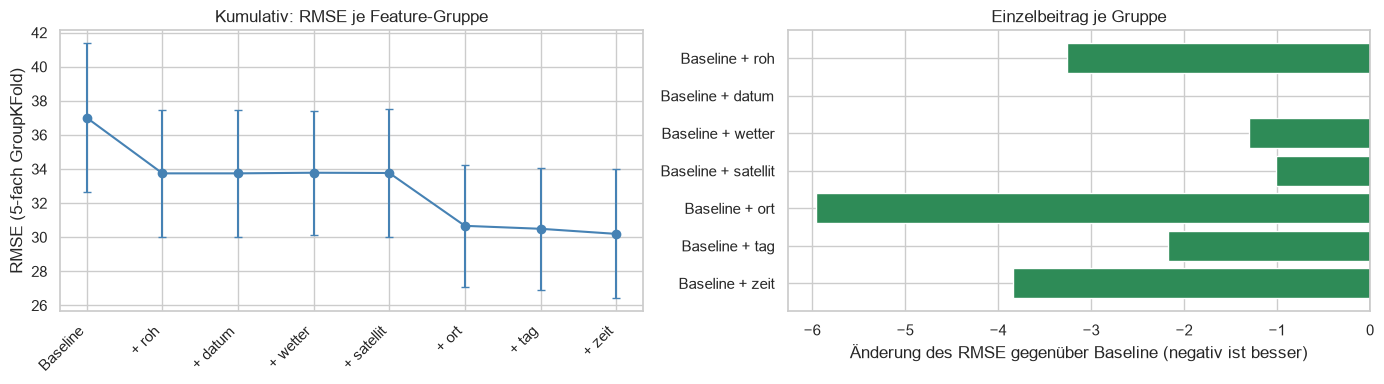

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].errorbar(range(len(cum)), cum["RMSE"], yerr=cum["RMSE Fold-Std"],
                 marker="o", capsize=3, color="steelblue")
axes[0].set_xticks(range(len(cum)))
axes[0].set_xticklabels(cum.index, rotation=45, ha="right")
axes[0].set_ylabel("RMSE (5-fach GroupKFold)")
axes[0].set_title("Kumulativ: RMSE je Feature-Gruppe")

delta = single["RMSE"] - cum["RMSE"].iloc[0]
axes[1].barh(single.index[::-1], delta[::-1],
             color=["seagreen" if d < 0 else "indianred" for d in delta[::-1]])
axes[1].axvline(0, color="black", lw=1)
axes[1].set_xlabel("Änderung des RMSE gegenüber Baseline (negativ ist besser)")
axes[1].set_title("Einzelbeitrag je Gruppe")
plt.tight_layout()
plt.show()

## 5. Feature-Auswahl per Permutation Importance (verschachtelt)

Mit vielen, teils redundanten Features kann Gradient Boosting überanpassen.
Wir lassen das Modell daher die Features bewerten. Damit die Auswahl die
Validierungsorte nicht „sieht“, läuft sie **innerhalb jedes Folds**:

1. Trainingsorte des Folds in einen inneren Teil (80 %) und eine Holdout-Gruppe (20 %, nach Orten) teilen.
2. Modell auf dem inneren Teil trainieren, Permutation Importance auf der Holdout-Gruppe messen.
3. Die Top-k Features wählen, mit dem **ganzen** Trainingsteil neu trainieren und auf dem äußeren Validierungsfold bewerten.

In [7]:
ALL = list(Xtr_all.columns)
KS = [10, 20, 30, 50, 80, len(ALL)]
rng = np.random.RandomState(RANDOM_STATE)

oof_k = {k: np.zeros(len(y)) for k in KS}
imp_folds = []
for i, (tr_idx, va_idx) in enumerate(folds):
    tr_places = place.iloc[tr_idx].unique()
    hold = rng.choice(tr_places, size=int(0.2 * len(tr_places)), replace=False)
    is_hold = place.iloc[tr_idx].isin(hold).to_numpy()
    inner, hold_idx = tr_idx[~is_hold], tr_idx[is_hold]

    m = make_model().fit(Xtr_all.iloc[inner], y.iloc[inner])
    pi = permutation_importance(m, Xtr_all.iloc[hold_idx], y.iloc[hold_idx],
                                n_repeats=3, random_state=RANDOM_STATE,
                                scoring="neg_root_mean_squared_error", n_jobs=1)
    imp = pd.Series(pi.importances_mean, index=ALL).sort_values(ascending=False)
    imp_folds.append(imp)

    for k in KS:
        sel = list(imp.index[:k])
        mk = make_model().fit(Xtr_all.iloc[tr_idx][sel], y.iloc[tr_idx])
        oof_k[k][va_idx] = mk.predict(Xtr_all.iloc[va_idx][sel])
    print(f"Fold {i + 1}/5 fertig")

sel_rows = []
for k in KS:
    fr = [np.sqrt(mean_squared_error(y.iloc[va], oof_k[k][va])) for _, va in folds]
    sel_rows.append({"Top-k Features": k,
                     "RMSE": np.sqrt(mean_squared_error(y, oof_k[k])),
                     "RMSE Fold-Std": np.std(fr),
                     "MAE": mean_absolute_error(y, oof_k[k]),
                     "R²": r2_score(y, oof_k[k])})
sel = pd.DataFrame(sel_rows).set_index("Top-k Features")
sel.round(2)

Fold 1/5 fertig


Fold 2/5 fertig


Fold 3/5 fertig


Fold 4/5 fertig


Fold 5/5 fertig


,RMSE,RMSE Fold-Std,MAE,R²
Top-k Features,,,,
10,33.50,4.98,22.70,0.49
20,31.00,4.40,20.88,0.56
30,30.49,4.52,20.41,0.58
50,30.28,4.18,20.22,0.58
80,30.22,3.91,20.31,0.58
142,30.25,3.76,20.21,0.58


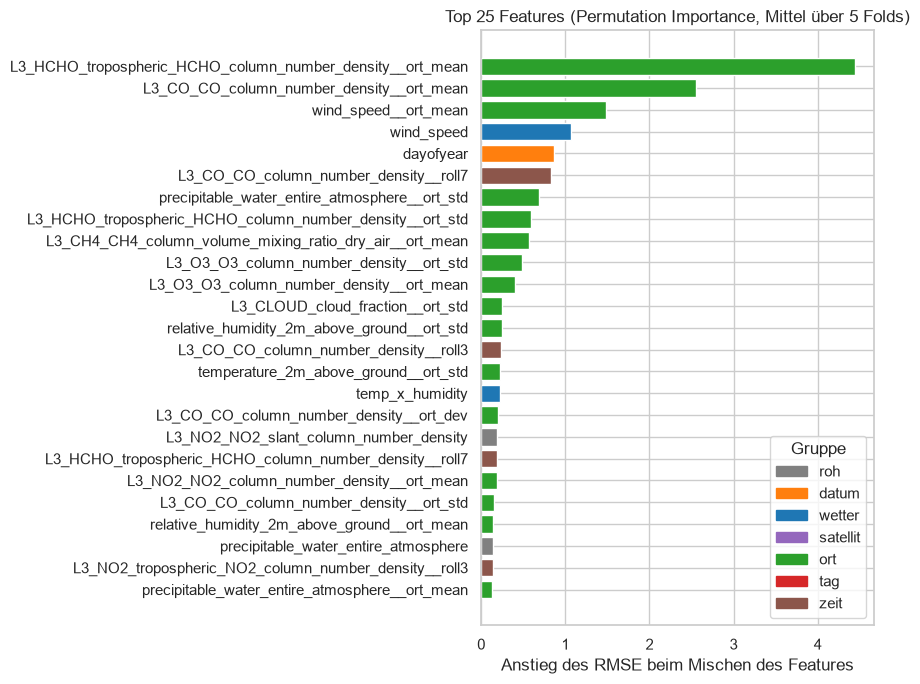

Anteil an der gesamten Importance je Gruppe:
ort         0.699
zeit        0.099
wetter      0.065
roh         0.059
datum       0.043
tag         0.029
satellit    0.006


In [8]:
# Mittlere Importance über die Folds und Anteil je Feature-Gruppe
imp_df = pd.concat(imp_folds, axis=1)
imp_mean = imp_df.mean(axis=1).sort_values(ascending=False)

group_of = {c: g for g, cs in groups.items() if g != "baseline" for c in cs}
top = imp_mean.head(25)
colors = {"roh": "gray", "datum": "tab:orange", "wetter": "tab:blue", "satellit": "tab:purple",
          "ort": "tab:green", "tag": "tab:red", "zeit": "tab:brown"}
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top.index[::-1], top.values[::-1],
        color=[colors[group_of[c]] for c in top.index[::-1]])
ax.set_xlabel("Anstieg des RMSE beim Mischen des Features")
ax.set_title("Top 25 Features (Permutation Importance, Mittel über 5 Folds)")
handles = [plt.Rectangle((0, 0), 1, 1, color=v) for v in colors.values()]
ax.legend(handles, colors.keys(), title="Gruppe", loc="lower right")
plt.tight_layout()
plt.show()

pos = imp_mean.clip(lower=0)
share = (pos.groupby(group_of).sum() / pos.sum()).sort_values(ascending=False)
print("Anteil an der gesamten Importance je Gruppe:")
print(share.round(3).to_string())

## 6. Finales Feature-Set

Wir wählen das kleinste k, dessen RMSE innerhalb eines Standardfehlers
(Fold-Std / √5) des besten Wertes liegt (Ein-Standardfehler-Regel, bevorzugt das
einfachere Modell), und nehmen die Features mit der höchsten mittleren Importance.

In [9]:
best_rmse = sel["RMSE"].min()
tol = sel.loc[sel["RMSE"].idxmin(), "RMSE Fold-Std"] / np.sqrt(len(folds))
k_final = int(sel[sel["RMSE"] <= best_rmse + tol].index.min())
final_features = list(imp_mean.index[:k_final])
print(f"Gewähltes k: {k_final} (bester RMSE {best_rmse:.2f}, Toleranz {tol:.2f})")

oof_final, row_final = cv_score(final_features, f"Final (Top {k_final})")
print(f"RMSE {row_final['RMSE']:.2f}, MAE {row_final['MAE']:.2f}, R² {row_final['R²']:.3f}")
print("Gruppen im finalen Set:", pd.Series([group_of.get(c, "baseline") for c in final_features]).value_counts().to_dict())

Path("models").mkdir(exist_ok=True)
with open("models/fe_selected_features.json", "w", encoding="utf-8") as f:
    json.dump(final_features, f, indent=2)
print("Gespeichert: models/fe_selected_features.json")

Gewähltes k: 20 (bester RMSE 30.22, Toleranz 1.75)


RMSE 30.26, MAE 20.59, R² 0.583
Gruppen im finalen Set: {'ort': 13, 'zeit': 3, 'wetter': 2, 'datum': 1, 'roh': 1}
Gespeichert: models/fe_selected_features.json


## 7. Vergleich und Fehleranalyse

Gegenüber der Baseline: Wo verbessert sich die Vorhersage, und bleibt das Problem
mit den Spitzenwerten?

,Features,RMSE,RMSE Fold-Std,MAE,R²
Variante,,,,,
Baseline (8 Features),8,37.00,4.38,26.17,0.38
Alle Features (142),142,30.20,3.78,20.17,0.58
Final (Top 20),20,30.26,3.99,20.59,0.58


,Zeilen,MAE_Baseline,MAE_Final,Anteil Fehler Final
bin,,,,
"(0, 25]",7718,25.08,17.68,0.16
"(25, 50]",7635,17.86,14.03,0.11
"(50, 100]",10265,18.82,17.67,0.19
"(100, 150]",2627,41.89,31.48,0.14
"(150, 200]",2056,64.72,46.85,0.22
"(200, 1000]",256,131.08,98.48,0.20


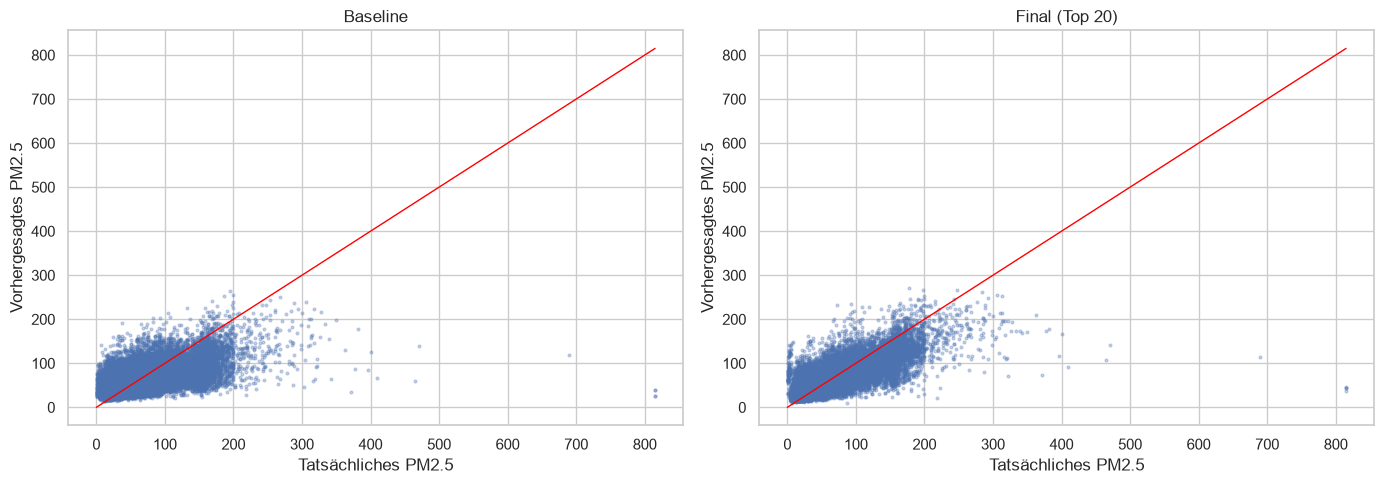

In [10]:
summary = pd.DataFrame([
    cv_score(groups["baseline"], "Baseline (8 Features)")[1],
    cv_score(list(Xtr_all.columns), f"Alle Features ({Xtr_all.shape[1]})")[1],
    row_final,
]).set_index("Variante")
display(summary.round(2))

bins = pd.cut(y, [0, 25, 50, 100, 150, 200, 1000])
err = pd.DataFrame({"bin": bins, "base": np.abs(y - oof_base), "fe": np.abs(y - oof_final),
                    "base_se": (y - oof_base) ** 2, "fe_se": (y - oof_final) ** 2})
by_bin = err.groupby("bin", observed=True).agg(
    Zeilen=("base", "size"), MAE_Baseline=("base", "mean"), MAE_Final=("fe", "mean"),
    SE_Base=("base_se", "sum"), SE_Final=("fe_se", "sum"))
by_bin["Anteil Fehler Final"] = (by_bin["SE_Final"] / by_bin["SE_Final"].sum()).round(3)
display(by_bin.drop(columns=["SE_Base", "SE_Final"]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, pred, title in zip(axes, [oof_base, oof_final], ["Baseline", f"Final (Top {k_final})"]):
    ax.scatter(y, pred, s=4, alpha=0.3)
    lim = [0, max(y.max(), pred.max())]
    ax.plot(lim, lim, color="red", lw=1)
    ax.set_xlabel("Tatsächliches PM2.5"); ax.set_ylabel("Vorhergesagtes PM2.5")
    ax.set_title(title)
plt.tight_layout()
plt.show()

## 8. Ergebnis und nächste Schritte

**RMSE (5-fach GroupKFold nach Ort, Gradient Boosting mit Standardparametern)**

| Feature-Set | Features | RMSE | R² |
| --- | --- | --- | --- |
| Baseline (8 Rohfeatures) | 8 | 37,0 | 0,38 |
| Alle Rohspalten ohne Geometrie | 39 | 33,7 | 0,48 |
| Alle Rohspalten + alle neuen Gruppen | 142 | **30,2** | 0,58 |
| Top 20 nach Permutation Importance | 20 | **30,3** | 0,58 |

Hinweis zur Referenz: Die gespeicherte Ausgabe von Meilenstein 2 (RMSE 33,4)
stammt aus einem Lauf mit allen 76 Rohspalten. Die 8 Features im aktuellen
Quelltext erreichen 37,0. Der faire Vergleich für die Rohspalten ist daher
33,7 (hier) gegen 33,4 (dort), ohne nennenswerten Unterschied.

**Beobachtungen**

- **Orts-Aggregate sind der mit Abstand wichtigste Baustein.** Mittelwert,
  Streuung und Abweichung der Satelliten- und Wetterwerte pro Ort senken den
  RMSE von 33,7 auf 30,7 und tragen etwa 70 % der gesamten Permutation
  Importance. Das passt zur EDA: Rund 62 % der Varianz liegen zwischen den
  Orten. Die Aggregate geben dem Modell eine Art Ortsprofil, ohne die Ortskennung
  zu verwenden (Train und Test haben keine gemeinsamen Orte).
- **Zeitliche Glättung** hilft allein deutlich (37,0 auf 33,2), bringt nach den
  Orts-Aggregaten aber nur noch etwa 0,3 RMSE. Beide Gruppen erfassen teils
  dieselbe Information (die verrauschten Satellitenwerte werden ruhiger).
- **Datum, abgeleitetes Wetter, Satellitenverhältnisse und Tages-Aggregate**
  bringen praktisch nichts (Änderungen unter 0,3 RMSE). Das liegt unter dem
  Rauschen der Folds (Fold-Std etwa 4) und ist nicht belastbar.
- **Weniger Features reichen:** Mit 20 von 142 Features bleibt der RMSE gleich.
  Die ehrliche, verschachtelte Schätzung liegt bei 31,0 (die Auswahl auf dem
  finalen Set nutzt alle Folds und ist etwas optimistisch).
- **Fehleranalyse:** Der MAE sinkt in allen Wertebereichen, bei Werten über 200
  von 131 auf 98. Die wenigen Spitzenwerte über 150 verursachen aber weiterhin
  etwa 40 % des quadratischen Fehlers. Das Modell unterschätzt Spitzen weiterhin.

**Grenzen**

- Die Orts-Aggregate setzen viele Tage pro Ort voraus. Train hat im Schnitt
  90 Tage pro Ort, Test etwa 90 Zeilen pro Ort (16.136 Zeilen bei 179 Orten).
  Für einen Ort mit nur wenigen Tagen wären sie unzuverlässig.
- Die Verbesserung von 33,7 auf 30,2 liegt knapp innerhalb einer Fold-Standardabweichung.
  Sie ist aber in jedem Wertebereich sichtbar und konsistent über die Schritte.
- Alle Modelle nutzen Standardparameter. Tuning kann Reihenfolge und Abstände ändern.

**Nächste Schritte (Meilenstein 3)**

- Das Feature-Set `models/fe_selected_features.json` (Top 20) als Eingabe für den
  Vergleich mehrerer Algorithmen mit Hyperparameter-Tuning nutzen.
- Weitere Orts-Aggregate testen (Median, Quantile, Anteil fehlender Tage) und
  räumliche Nachbarschaft nutzen, falls Koordinaten verfügbar sind.
- Spitzen gezielt angehen: `log1p(target)`, gewichteten Loss oder Quantil-Ziel.
